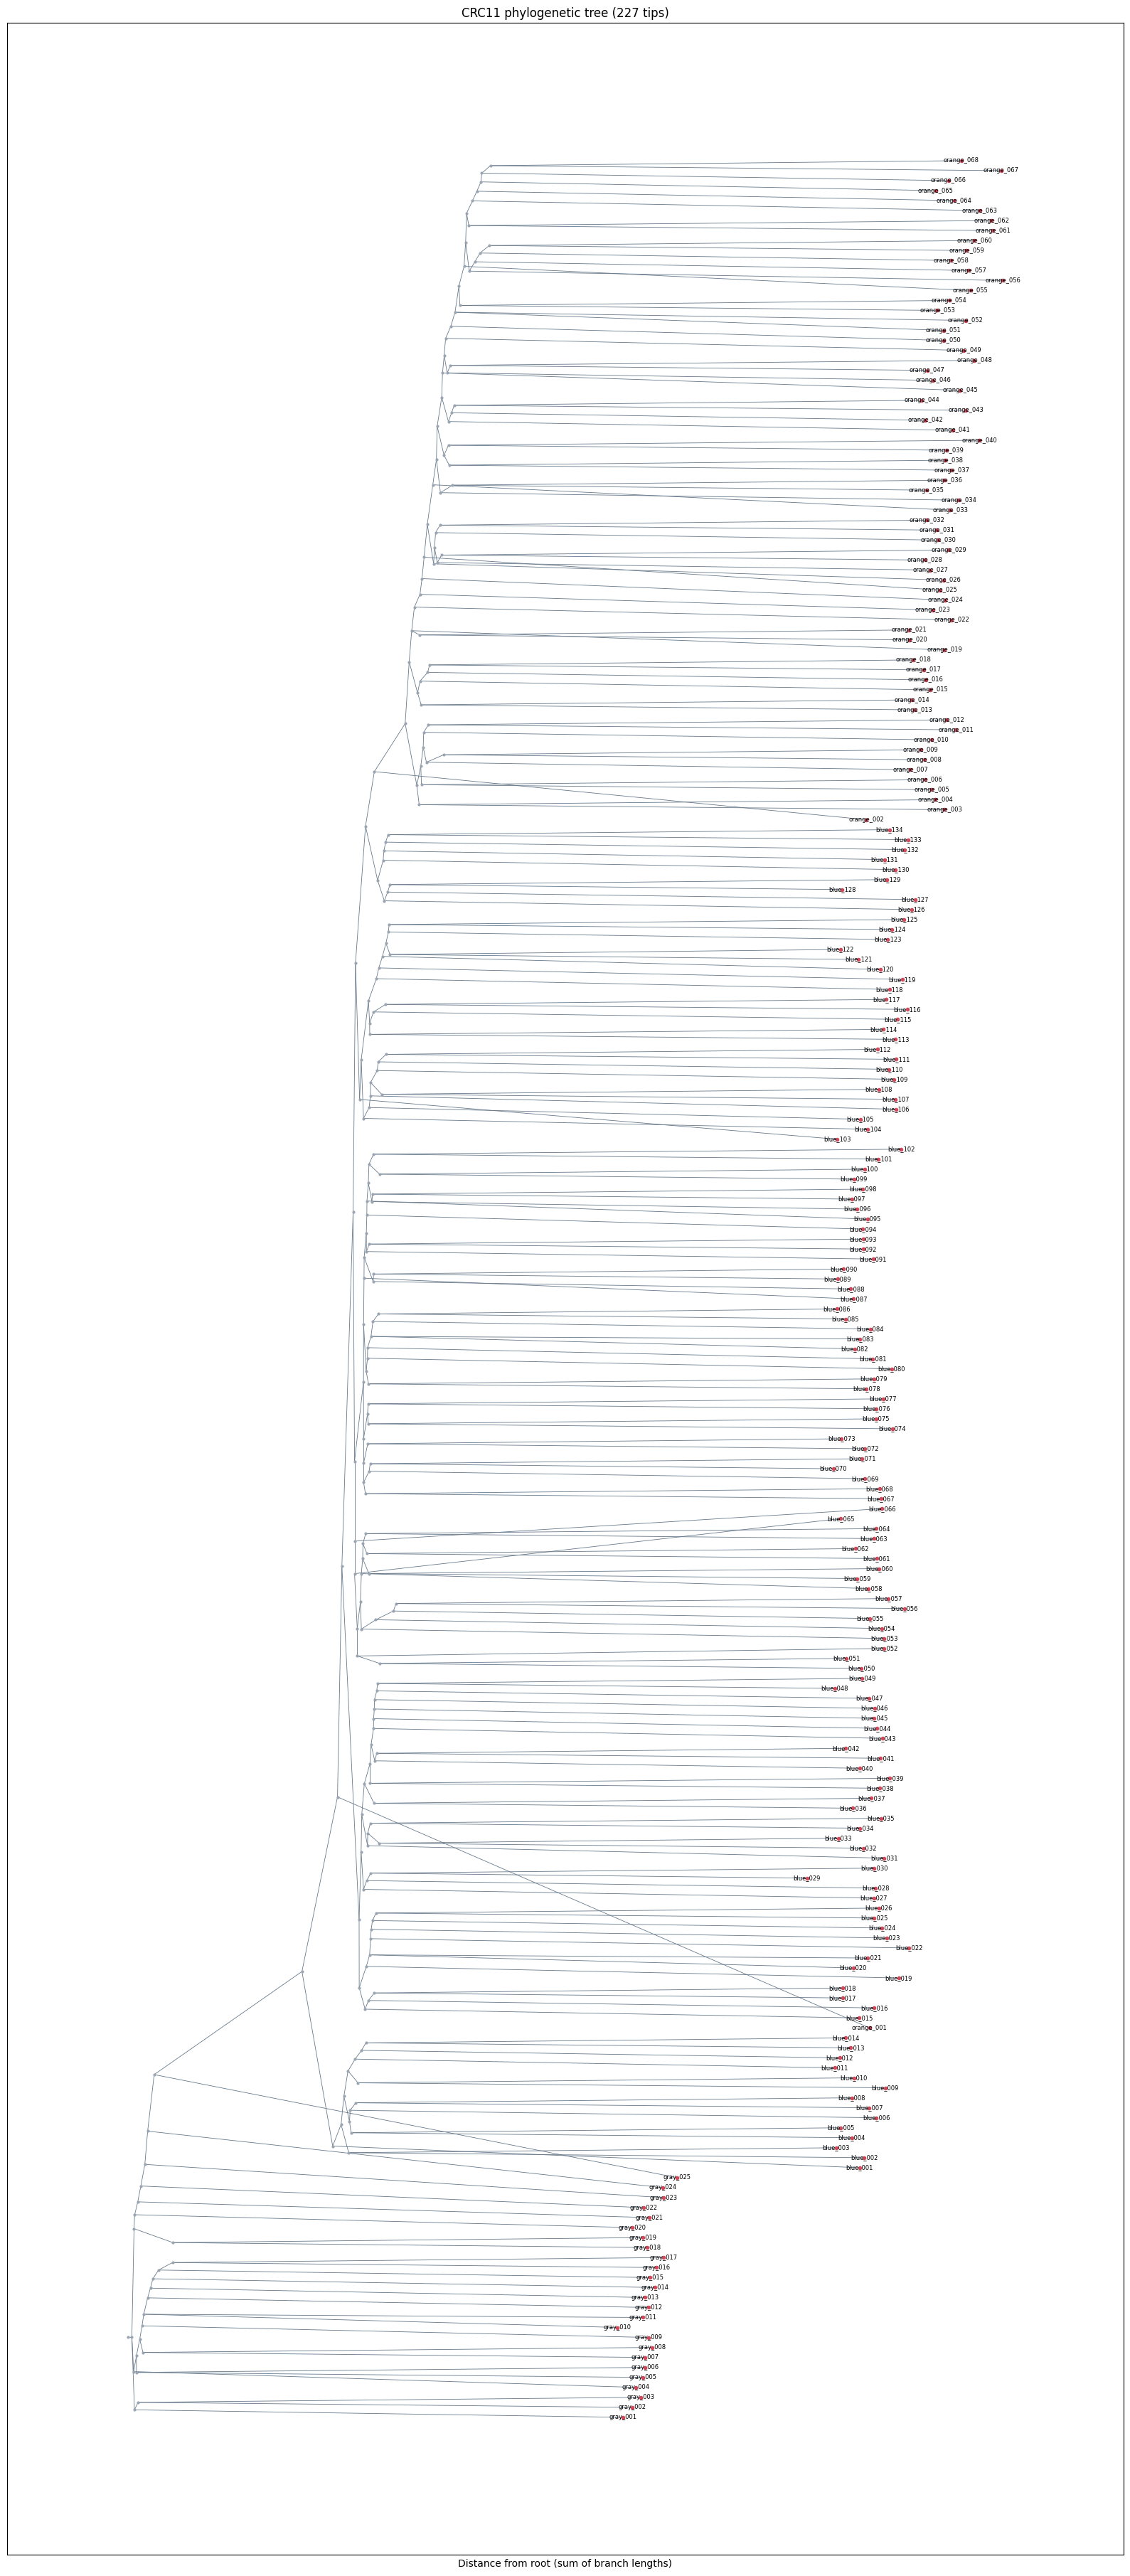

Loaded a directed tree with 448 nodes and 447 edges.


In [17]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
from Bio import Phylo


tree_path = Path("../data/sgootr/CRC11.nwk")
tree = Phylo.read(tree_path, "newick")
stem_length = 1e-1
clades = list(tree.find_clades(order="preorder"))
node_ids = {id(clade): index for index, clade in enumerate(clades)}

tree_graph = nx.DiGraph()
for clade in clades:
    node = node_ids[id(clade)]
    tree_graph.add_node(node, label=clade.name or "", terminal=clade.is_terminal())
    for child in clade.clades:
        tree_graph.add_edge(node, node_ids[id(child)], length=child.branch_length or 0.0)

original_root = node_ids[id(tree.root)]
stem_node = len(node_ids)
tree_graph.add_node(stem_node, label="stem", terminal=False)
tree_graph.add_edge(stem_node, original_root, length=stem_length)
root = stem_node
leaf_nodes = [node for node, data in tree_graph.nodes(data=True) if data["terminal"]]
depths = nx.single_source_dijkstra_path_length(tree_graph, root, weight="length")
positions = {}

for y, clade in enumerate(tree.get_terminals()):
    node = node_ids[id(clade)]
    positions[node] = (depths[node], y)

for clade in reversed(clades):
    node = node_ids[id(clade)]
    if not clade.is_terminal():
        child_y = [positions[node_ids[id(child)]][1] for child in clade.clades]
        positions[node] = (depths[node], sum(child_y) / len(child_y))

positions[stem_node] = (depths[stem_node], positions[original_root][1])

fig, ax = plt.subplots(figsize=(16, max(8, len(leaf_nodes) * 0.16)))
nx.draw_networkx_edges(tree_graph, positions, ax=ax, arrows=False, width=0.6, edge_color="#66788a")
nx.draw_networkx_nodes(
    tree_graph,
    positions,
    nodelist=[node for node in tree_graph if not tree_graph.nodes[node]["terminal"]],
    ax=ax,
    node_size=4,
    node_color="#9aa5b1",
)
nx.draw_networkx_nodes(
    tree_graph,
    positions,
    nodelist=leaf_nodes,
    ax=ax,
    node_size=9,
    node_color="#d1495b",
)
nx.draw_networkx_labels(
    tree_graph,
    positions,
    labels={node: tree_graph.nodes[node]["label"] for node in leaf_nodes},
    ax=ax,
    font_size=6,
)
ax.set_title(f"CRC11 phylogenetic tree ({len(leaf_nodes)} tips)")
ax.set_xlabel("Distance from root (sum of branch lengths)")
ax.set_yticks([])
ax.margins(x=0.08, y=0.01)
fig.tight_layout()
plt.show()

print(f"Loaded a directed tree with {tree_graph.number_of_nodes()} nodes and {tree_graph.number_of_edges()} edges.")

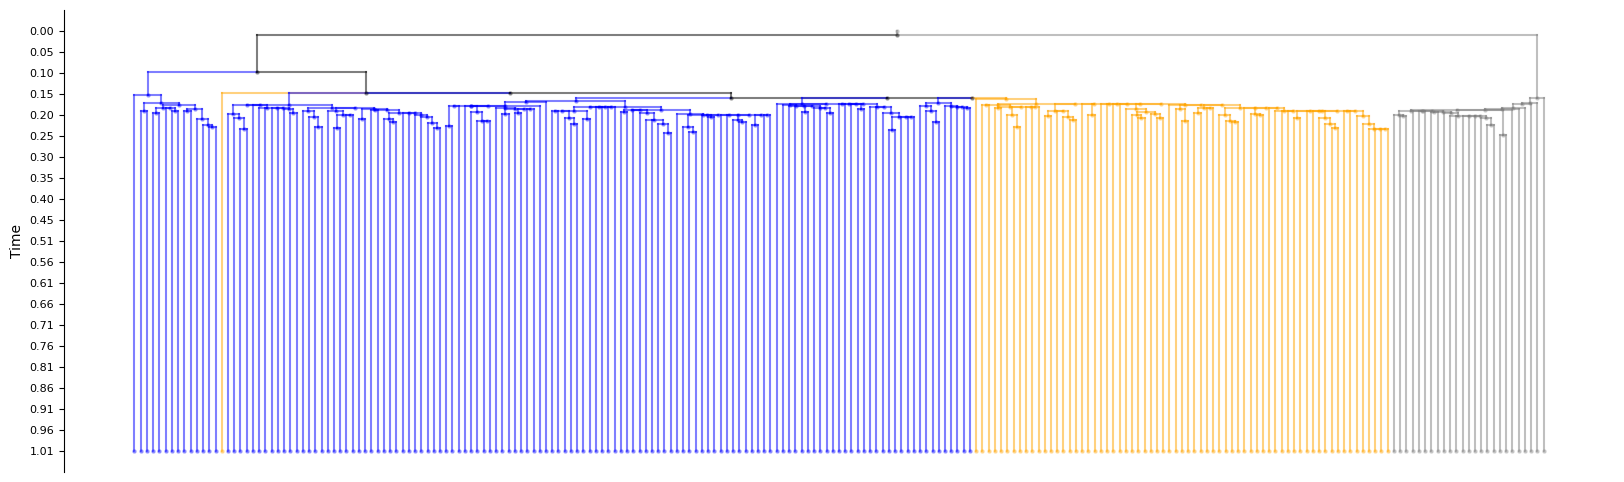

Tip states: {'PT': 134, 'LN': 68, 'NC': 25}.
Saved LSD2 ultrametric Newick to ../data/sgootr/CRC11_ultrametric.nwk.
Graph: 449 nodes, 448 edges, 227 tips.
Root-to-tip distance range: 1.05e-06 (tolerance 1e-5).
Dating assumptions: relative dates, all tips equal; sequence length = 1000; root estimated by LSD2.


In [18]:
import shutil
import subprocess
import sys
import tempfile
from collections import Counter

sys.path.append("../src")
from plotters import color_map, draw_ultrametric_tree
color_map.update({"NC": "gray", "PT": "blue", "LN": "orange"})

tree_path = Path("../data/sgootr/CRC11.nwk")
ultrametric_path = Path("../data/sgootr/CRC11_ultrametric.nwk")
stem_length = 1e-1
tree_with_stem = Phylo.read(tree_path, "newick")
if tree_with_stem.root.branch_length not in (None, 0.0):
    raise ValueError(f"Input tree already has a stem length: {tree_with_stem.root.branch_length}")
tree_with_stem.root.branch_length = stem_length
lsd2_executable = shutil.which("lsd2")
if lsd2_executable is None:
    raise FileNotFoundError("LSD2 was not found on PATH; install lsd2 before running this cell.")

with tempfile.TemporaryDirectory() as temporary_directory:
    stem_tree_path = Path(temporary_directory) / "CRC11_with_stem.nwk"
    Phylo.write(tree_with_stem, stem_tree_path, "newick", format_branch_length="%1.10f")
    serialized_stem_length = Phylo.read(stem_tree_path, "newick").root.branch_length
    if serialized_stem_length is None or abs(serialized_stem_length - stem_length) > 1e-12:
        raise ValueError(f"Failed to preserve the stem length in {stem_tree_path}.")

    output_prefix = Path(temporary_directory) / "CRC11_ultrametric"
    command = [
        lsd2_executable,
        "-i",
        str(stem_tree_path.resolve()),
        "-o",
        str(output_prefix),
        "-s",
        "1000",
        "-r",
        "a",
        "-l",
        "-1",
    ]
    result = subprocess.run(command, capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(f"LSD2 failed:\n{result.stderr or result.stdout}")
    dated_nexus_path = Path(f"{output_prefix}.date.nexus")
    if not dated_nexus_path.is_file():
        raise FileNotFoundError(f"LSD2 did not create the expected tree: {dated_nexus_path}")
    dated_tree = Phylo.read(dated_nexus_path, "nexus")

source_tip_names = {tip.name for tip in Phylo.read(tree_path, "newick").get_terminals()}
dated_tip_names = {tip.name for tip in dated_tree.get_terminals()}
if source_tip_names != dated_tip_names:
    raise ValueError("The LSD2 output tip labels do not match the input tree.")

Phylo.write(dated_tree, ultrametric_path, "newick", format_branch_length="%1.10f")
ultrametric_tree = Phylo.read(ultrametric_path, "newick")
ultrametric_clades = list(ultrametric_tree.find_clades(order="preorder"))
ultrametric_node_ids = {id(clade): index for index, clade in enumerate(ultrametric_clades)}

state_by_prefix = {"gray": "NC", "blue": "PT", "orange": "LN"}
tip_states = {}
for clade in ultrametric_tree.get_terminals():
    state = next(
        (state for prefix, state in state_by_prefix.items() if clade.name.startswith(f"{prefix}_")),
        None,
    )
    if state is None:
        raise ValueError(f"No state mapping for tip label: {clade.name}")
    tip_states[id(clade)] = state

clade_states = {}
for clade in reversed(ultrametric_clades):
    if clade.is_terminal():
        clade_states[id(clade)] = tip_states[id(clade)]
    else:
        child_states = {clade_states[id(child)] for child in clade.clades}
        clade_states[id(clade)] = child_states.pop() if len(child_states) == 1 else None

tree_graph = nx.DiGraph()
for clade in ultrametric_clades:
    node = ultrametric_node_ids[id(clade)]
    tree_graph.add_node(
        node,
        label=clade.name or "",
        terminal=clade.is_terminal(),
        state=clade_states[id(clade)],
    )
    for child in clade.clades:
        tree_graph.add_edge(
            node,
            ultrametric_node_ids[id(child)],
            length=child.branch_length or 0.0,
        )

original_root_id = ultrametric_node_ids[id(ultrametric_tree.root)]
stem_node_id = max(tree_graph.nodes) + 1
tree_graph.add_node(stem_node_id, label="stem", terminal=False, state="NC")
tree_graph.add_edge(stem_node_id, original_root_id, length=stem_length)
root = stem_node_id
leaf_nodes = [node for node, data in tree_graph.nodes(data=True) if data["terminal"]]
depths = nx.single_source_dijkstra_path_length(tree_graph, root, weight="length")
tip_depths = [depths[node] for node in leaf_nodes]
tip_depth_range = max(tip_depths) - min(tip_depths)
if tip_depth_range > 1e-5:
    raise ValueError(f"LSD2 output is not ultrametric: root-to-tip range is {tip_depth_range:.3g}.")

node_colors = [
    (node, data["state"])
    for node, data in tree_graph.nodes(data=True)
    if data["state"] is not None
]
draw_ultrametric_tree(
    tree_graph,
    root=root,
    add_labels=False,
    figsize=(20, 6),
    node_colors=node_colors,
)
print(f"Tip states: {dict(Counter(tip_states.values()))}.")

print(f"Saved LSD2 ultrametric Newick to {ultrametric_path}.")
print(f"Graph: {tree_graph.number_of_nodes()} nodes, {tree_graph.number_of_edges()} edges, {len(leaf_nodes)} tips.")
print(f"Root-to-tip distance range: {tip_depth_range:.3g} (tolerance 1e-5).")
print("Dating assumptions: relative dates, all tips equal; sequence length = 1000; root estimated by LSD2.")

from dataprocessor import export_tree
from likelihood import add_node_times

state_id_by_name = {"NC": 0, "PT": 1, "LN": 2}
inference_tree = tree_graph.copy()
for node, data in inference_tree.nodes(data=True):
    data["is_leaf"] = data["terminal"]
    data["state"] = -1

for tip in ultrametric_tree.get_terminals():
    state_name = tip_states[id(tip)]
    inference_tree.nodes[ultrametric_node_ids[id(tip)]]["state"] = state_id_by_name[state_name]

inference_tree = add_node_times(inference_tree, root=root, reverse=True)
inference_dir = Path("../data/sgootr/inference")
inference_dir.mkdir(parents=True, exist_ok=True)
nodes_path = inference_dir / "nodes.csv"
edges_path = inference_dir / "edges.csv"
transition_edges_path = inference_dir / "transition_edges.txt"
export_tree(inference_tree, node_file=str(nodes_path), edge_file=str(edges_path))
transition_edges_path.write_text("0 1\n1 2\n")

print(f"Exported inference nodes to {nodes_path}.")
print(f"Exported inference edges to {edges_path}.")
print(f"State IDs: NC=0, PT=1, LN=2; transition edges: 0->1, 1->2.")

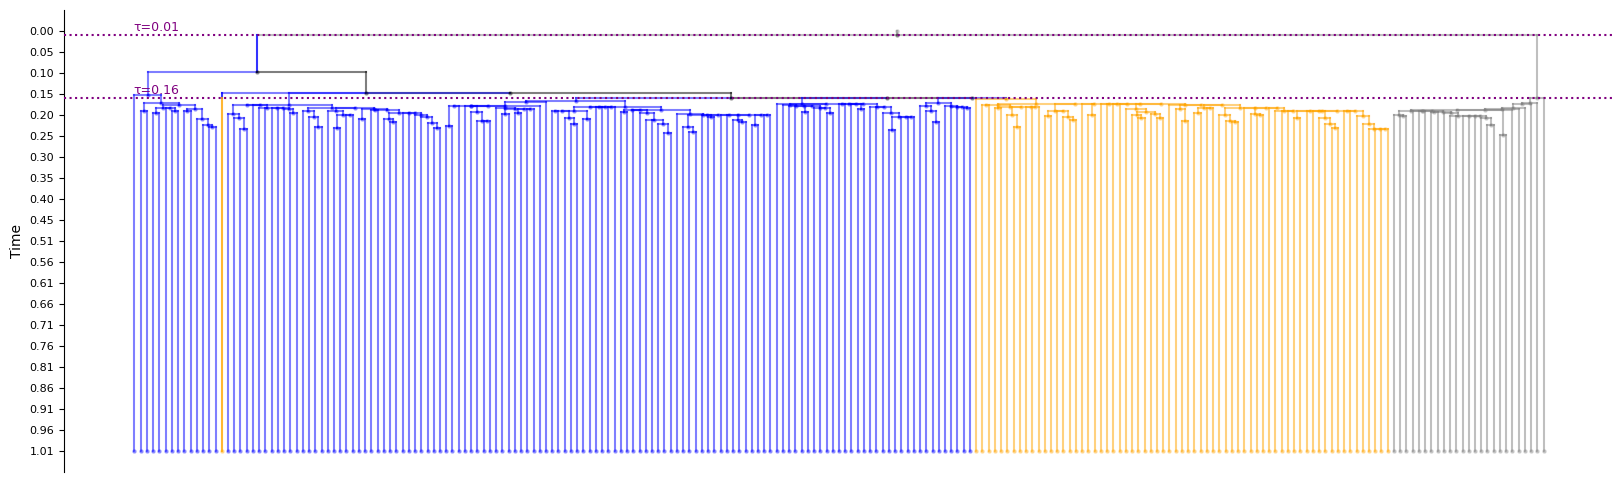

MACH2 solution: 0-T-0.refined.tree
MACH2-inferred transition edges: 3
Plotted 3 transition edges and 2 grouped times.
Grouped root-relative transition times: [0.01, 0.16065977]
Saved edge details to /Users/samin/workspace/phylodynamic-carta/data/sgootr/CRC11_transitions.csv.
Saved transition times to /Users/samin/workspace/phylodynamic-carta/data/sgootr/CRC11_transition-times.txt.


In [19]:
import shutil
import subprocess
import sys
import tempfile

import pandas as pd

project_root = Path('..').resolve()
mach2_executable = shutil.which('mach2') or str(project_root / '.venv' / 'bin' / 'mach2')
if not Path(mach2_executable).is_file():
    raise FileNotFoundError('MACH2 was not found on PATH or in the project .venv/bin directory.')

state_id_by_name = {'NC': 0, 'PT': 1, 'LN': 2}
state_name_by_id = {state_id: state for state, state_id in state_id_by_name.items()}
mach2_id_by_node_id = {
    node_id: node_id + 1 for node_id in ultrametric_node_ids.values()
}
original_root_id = ultrametric_node_ids[id(ultrametric_tree.root)]
mach2_edges = [(0, mach2_id_by_node_id[original_root_id])] + [
    (
        mach2_id_by_node_id[ultrametric_node_ids[id(parent)]],
        mach2_id_by_node_id[ultrametric_node_ids[id(child)]],
    )
    for parent in ultrametric_clades
    for child in parent.clades
]
mach2_tip_labels = [
    (
        mach2_id_by_node_id[ultrametric_node_ids[id(tip)]],
        state_id_by_name[tip_states[id(tip)]],
    )
    for tip in ultrametric_tree.get_terminals()
]

with tempfile.TemporaryDirectory(prefix='sgootr-mach2-') as temporary_directory:
    temporary_directory = Path(temporary_directory)
    mach2_tree_path = temporary_directory / 'CRC11.tree'
    mach2_labeling_path = temporary_directory / 'CRC11.labeling'
    mach2_output_path = temporary_directory / 'output'
    mach2_output_path.mkdir()

    mach2_tree_path.write_text(''.join(f'{parent}\t{child}\n' for parent, child in mach2_edges))
    mach2_labeling_path.write_text(''.join(f'{node}\t{state}\n' for node, state in mach2_tip_labels))

    mach2_result = subprocess.run(
        [
            mach2_executable,
            str(mach2_tree_path),
            str(mach2_labeling_path),
            '-p',
            '0',
            '-o',
            str(mach2_output_path),
        ],
        capture_output=True,
        text=True,
        check=False,
    )
    if mach2_result.returncode != 0:
        raise RuntimeError(
            f'MACH2 failed with exit code {mach2_result.returncode}:\n'
            f'{mach2_result.stderr.strip() or mach2_result.stdout.strip()}'
        )

    refined_tree_paths = sorted(mach2_output_path.glob('*-T-0.refined.tree'))
    if len(refined_tree_paths) != 1:
        raise FileNotFoundError(
            f'Expected one first-solution MACH2 refined tree, found {len(refined_tree_paths)}.'
        )
    refined_tree_path = refined_tree_paths[0]
    mach2_prefix = str(refined_tree_path)[:-len('.refined.tree')]
    mach2_refined_tree = pd.read_csv(
        refined_tree_path,
        sep=chr(9),
        header=None,
        names=['parent', 'child', 'mach2_time'],
        dtype={'parent': str, 'child': str},
    )
    mach2_location_labels = pd.read_csv(
        f'{mach2_prefix}.location.labeling',
        sep=chr(9),
        header=None,
        names=['node_id', 'state_id'],
        dtype={'node_id': str, 'state_id': int},
    )
    mach2_node_origins = pd.read_csv(
        f'{mach2_prefix}.nodes',
        sep=chr(9),
        header=None,
        names=['node_id', 'origin_node_id'],
        dtype=str,
    )

origin_by_node = dict(zip(mach2_node_origins['node_id'], mach2_node_origins['origin_node_id']))
state_by_node = dict(zip(mach2_location_labels['node_id'], mach2_location_labels['state_id']))
time_by_node = {'0': 0.0}
time_by_node.update(
    {
        str(mach2_node_id): depths[node_id]
        for node_id, mach2_node_id in mach2_id_by_node_id.items()
    }
)
migration_edges = mach2_refined_tree.loc[mach2_refined_tree['mach2_time'] != -1].copy()

transition_records = []
for edge_index, edge in migration_edges.iterrows():
    parent_origin = origin_by_node[edge['parent']]
    child_origin = origin_by_node[edge['child']]
    state_0 = state_name_by_id[state_by_node[edge['parent']]]
    state_1 = state_name_by_id[state_by_node[edge['child']]]
    time_0 = time_by_node[parent_origin]
    time_1 = time_by_node[child_origin]
    transition_records.append(
        {
            'edge_index': edge_index,
            'parent': edge['parent'],
            'child': edge['child'],
            'state_0': state_0,
            'state_1': state_1,
            'interval_start': min(time_0, time_1),
            'interval_end': max(time_0, time_1),
            'midpoint': (time_0 + time_1) / 2,
        }
    )

transition_edges = pd.DataFrame(
    transition_records,
    columns=[
        'edge_index', 'parent', 'child', 'state_0', 'state_1',
        'interval_start', 'interval_end', 'midpoint',
    ],
)
transition_groups = []
for (state_0, state_1), state_edges in transition_edges.groupby(
    ['state_0', 'state_1'], sort=False
):
    overlap_group = []
    shared_start = None
    shared_end = None
    for _, edge in state_edges.sort_values('interval_end').iterrows():
        if overlap_group:
            next_start = max(shared_start, edge['interval_start'])
            next_end = min(shared_end, edge['interval_end'])
        else:
            next_start = edge['interval_start']
            next_end = edge['interval_end']

        if overlap_group and next_start < next_end:
            overlap_group.append(edge['edge_index'])
            shared_start = next_start
            shared_end = next_end
        else:
            if overlap_group:
                transition_groups.append(
                    (state_0, state_1, shared_start, shared_end, overlap_group)
                )
            overlap_group = [edge['edge_index']]
            shared_start = edge['interval_start']
            shared_end = edge['interval_end']

    if overlap_group:
        transition_groups.append(
            (state_0, state_1, shared_start, shared_end, overlap_group)
        )

transition_time_by_edge = {}
for state_0, state_1, shared_start, shared_end, edge_indices in transition_groups:
    group_time = stem_length / 2 if shared_start == 0 else shared_start
    for edge_index in edge_indices:
        transition_time_by_edge[edge_index] = group_time

transition_edges['transition_time'] = transition_edges['edge_index'].map(
    transition_time_by_edge
)
transition_times = sorted(
    [
        stem_length / 2 if shared_start == 0 else shared_start
        for _, _, shared_start, _, _ in transition_groups
    ]
)

transition_edges_path = project_root / 'data' / 'sgootr' / 'CRC11_transitions.csv'
transition_times_path = project_root / 'data' / 'sgootr' / 'CRC11_transition-times.txt'
transition_edges[
    ['parent', 'child', 'state_0', 'state_1', 'interval_start', 'interval_end', 'transition_time']
].to_csv(transition_edges_path, index=False)
transition_times_path.write_text(''.join(f'{time:.10g}\n' for time in transition_times))

plot_node_by_input_id = {'0': stem_node_id}
plot_node_by_input_id.update(
    {
        str(mach2_node_id): node_id
        for node_id, mach2_node_id in mach2_id_by_node_id.items()
    }
)
plot_root_time = tree_graph.nodes[root].get('T', 1.0)
plot_transition_edges = []
unplotted_transition_edges = 0
for edge in transition_edges.itertuples(index=False):
    parent_origin = origin_by_node[edge.parent]
    child_origin = origin_by_node[edge.child]
    parent = plot_node_by_input_id[parent_origin]
    child = plot_node_by_input_id[child_origin]
    if tree_graph.has_edge(parent, child):
        plot_transition_edges.append(
            (
                parent,
                child,
                edge.state_0,
                edge.state_1,
                plot_root_time - edge.transition_time,
            )
        )
    else:
        unplotted_transition_edges += 1

if unplotted_transition_edges:
    print(
        f'Warning: {unplotted_transition_edges} MACH2 transition edges do not map '
        'to an edge in the plotted tree.'
    )

draw_ultrametric_tree(
    tree_graph,
    root=root,
    add_labels=False,
    figsize=(20, 6),
    node_colors=node_colors,
    transition_times_of_edges=plot_transition_edges,
    diff_times=transition_times,
)

print(f'MACH2 solution: {refined_tree_path.name}')
print(f'MACH2-inferred transition edges: {len(transition_edges)}')
print(f'Plotted {len(plot_transition_edges)} transition edges and {len(transition_times)} grouped times.')
print(f'Grouped root-relative transition times: {transition_times}')
print(f'Saved edge details to {transition_edges_path}.')
print(f'Saved transition times to {transition_times_path}.')